In [1]:
# 第一部分：导入必要的库
# ============================================

import mindspore as ms
from mindspore import nn
import mindspore.dataset as ds
import mindspore.ops as P
from mindspore.nn import SoftmaxCrossEntropyWithLogits
from mindspore.common.initializer import Normal

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

from mindquantum.core.circuit import Circuit, UN
from mindquantum.core.gates import H, RY, RZ, CNOT, Rxx, Ryy, Rzz
from mindquantum.core.parameterresolver import PRGenerator
from mindquantum.core.operators import QubitOperator, Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.framework import MQLayer
from mindspore import Tensor
import warnings
warnings.filterwarnings('ignore')

# 尝试导入umap（如果可用）
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print("umap-learn 未安装。如需使用UMAP降维，请安装: pip install umap-learn")

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei']  # 使用黑体显示中文
plt.rcParams['axes.unicode_minus'] = False    # 解决负号显示异常

[WARNING] ME(42816:34592,MainProcess):2026-10-12-19:00:12.740.000 [mindspore\run_check\_check_version.py:543] The directory C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 does not contain the typical file structure of CUDA
[ERROR] ME(42816:34592,MainProcess):2026-10-12-19:00:12.740.000 [mindspore\run_check\_check_version.py:582] CUDA_PATH C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 is not safe, skip add cuda path.


In [2]:
# 第二部分：可调参数配置区（二分类 airplane/automobile）
# ============================================

# 数据相关参数
SAMPLE_RATIO = 1            # 数据采样比例（此处不使用，保留）
TEST_SIZE = 0.2                # 测试集比例（此处不使用）
PCA_COMPONENTS = 8             # 降维目标维度（与量子比特数一致）
BATCH_SIZE = 32                 # 批处理大小

# 降维方法选择（这里只运行自编码器）
DIM_REDUCTION_METHODS = ['autoencoder']   # 将要运行的降维方法列表
RUN_PCA = False

# 自编码器训练参数（当使用自编码器时）
AUTOENCODER_EPOCHS = 50        # 自编码器训练轮数
AUTOENCODER_LR = 0.001         # 自编码器学习率
AUTOENCODER_HIDDEN_DIMS = [256, 64]  # 编码器隐藏层维度（输入维度 -> 256 -> 64 -> 8）

# 量子电路参数
NUM_QUBITS = 8                  # 量子比特数
FIXED_ANSAYZ_TYPE = 'sequential_su4'  # 固定Ansatz类型
FIXED_LAYERS = 2                 # 固定层数

# 训练参数
NUM_CLASSES = 2                  # 二分类：airplane / automobile
NUM_EPOCHS = 150                 # 训练轮数
LEARNING_RATE = 0.01             # 学习率
PARALLEL_WORKER = 2              # 并行工作器数量

# MindSpore配置
MS_MODE = ms.PYNATIVE_MODE        # 运行模式
MS_DEVICE = "CPU"                 # 设备目标
SEED = 42                         # 随机种子

# 初始化设置
# ============================================
ms.set_context(mode=MS_MODE, device_target=MS_DEVICE)
ms.set_seed(SEED)
np.random.seed(SEED)

[WARNING] ME(42816:34592,MainProcess):2026-10-12-19:00:19.941.000 [mindspore\context.py:1334] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [3]:
# 第三部分：数据加载和处理函数（CIFAR-10 二分类版 + 自编码器）
# ============================================
import os
from sklearn.preprocessing import MinMaxScaler
from torchvision.datasets import CIFAR10

import mindspore as ms
from mindspore import nn, ops, Tensor
from mindspore.common.initializer import HeNormal
import mindspore.dataset as ds

def load_cifar10_binary():
    """
    加载 CIFAR-10 并仅保留 airplane (0) 和 automobile (1)，
    重映射标签为 0 / 1，采样策略：
        - 训练集：每类 640 张（共 1280 张）
        - 测试集：每类 100 张（共 200 张）
    """
    data_dir = "./CIFAR10"
    os.makedirs(data_dir, exist_ok=True)

    # 设置国内镜像加速下载（阿里云）
    os.environ['CIFAR10_MIRROR'] = 'https://mirrors.aliyun.com/pytorch/'

    print("正在加载 CIFAR-10 二分类数据集 (airplane/automobile)...")
    train_set = CIFAR10(root=data_dir, train=True, download=True)
    test_set = CIFAR10(root=data_dir, train=False, download=True)

    train_images = train_set.data  # (50000, 32, 32, 3)
    train_labels = np.array(train_set.targets)
    test_images = test_set.data
    test_labels = np.array(test_set.targets)

    # 筛选 airplane (0) 和 automobile (1)
    target_classes = [0, 1]  # airplane=0, automobile=1
    train_mask = np.isin(train_labels, target_classes)
    test_mask = np.isin(test_labels, target_classes)

    train_images = train_images[train_mask]
    train_labels = train_labels[train_mask]
    test_images = test_images[test_mask]
    test_labels = test_labels[test_mask]

    # 标签重映射：0 -> 0, 1 -> 1（实际不变，但确保只含0/1）
    # 若未来换其他类别可借此重新编号，这里直接保持。
    # 你可以在这里显式映射：train_labels = (train_labels == 0).astype(np.int32) 等
    # 为通用性，我们直接使用原始标签（已为0/1），但仍做一次规范化
    label_map = {0: 0, 1: 1}
    train_labels = np.vectorize(label_map.get)(train_labels)
    test_labels = np.vectorize(label_map.get)(test_labels)

    # 展平 + 归一化
    all_train_x = train_images.reshape(len(train_images), -1).astype(np.float32) / 255.0
    all_test_x = test_images.reshape(len(test_images), -1).astype(np.float32) / 255.0

    # 按类别采样：每类训练 640，测试 100
    train_per_class = 640
    test_per_class = 100
    train_x, train_y = [], []
    test_x, test_y = [], []
    rng = np.random.RandomState(SEED)

    for c in [0, 1]:
        c_train_idx = np.where(train_labels == c)[0]
        rng.shuffle(c_train_idx)
        train_idx = c_train_idx[:train_per_class]
        train_x.append(all_train_x[train_idx])
        train_y.append(train_labels[train_idx])

        c_test_idx = np.where(test_labels == c)[0]
        rng.shuffle(c_test_idx)
        test_idx = c_test_idx[:test_per_class]
        test_x.append(all_test_x[test_idx])
        test_y.append(test_labels[test_idx])

    train_x = np.concatenate(train_x, axis=0)
    train_y = np.concatenate(train_y, axis=0)
    test_x = np.concatenate(test_x, axis=0)
    test_y = np.concatenate(test_y, axis=0)

    shuffle_idx = rng.permutation(len(train_x))
    train_x, train_y = train_x[shuffle_idx], train_y[shuffle_idx]

    print(f"二分类采样完成：训练集 {train_x.shape[0]} 张，测试集 {test_x.shape[0]} 张")
    print(f"训练集类别分布: {np.bincount(train_y)}")
    print(f"测试集类别分布: {np.bincount(test_y)}")
    return train_x, train_y, test_x, test_y

class Autoencoder(nn.Cell):
    """自编码器模型，用于降维（与 MNIST 实验结构一致）"""
    def __init__(self, input_dim=3072, hidden_dims=[256, 64], latent_dim=8):
        super(Autoencoder, self).__init__()
        # 编码器
        encoder_layers = []
        prev_dim = input_dim
        for h_dim in hidden_dims:
            encoder_layers.append(nn.Dense(prev_dim, h_dim, weight_init=HeNormal()))
            encoder_layers.append(nn.ReLU())
            prev_dim = h_dim
        encoder_layers.append(nn.Dense(prev_dim, latent_dim, weight_init=HeNormal()))
        self.encoder = nn.SequentialCell(encoder_layers)

        # 解码器
        decoder_layers = []
        prev_dim = latent_dim
        for h_dim in reversed(hidden_dims):
            decoder_layers.append(nn.Dense(prev_dim, h_dim, weight_init=HeNormal()))
            decoder_layers.append(nn.ReLU())
            prev_dim = h_dim
        decoder_layers.append(nn.Dense(prev_dim, input_dim, weight_init=HeNormal()))
        self.decoder = nn.SequentialCell(decoder_layers)

    def construct(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return encoded, decoded

def train_autoencoder(train_images, epochs=50, lr=0.001, batch_size=128):
    """训练自编码器，返回编码器和用于自编码器输入的 scaler（与 MNIST 实验一致）"""
    # 先对训练图像归一化到[0,1]（自编码器输入需要）
    scaler_for_ae = MinMaxScaler(feature_range=(0, 1))
    train_images_scaled = scaler_for_ae.fit_transform(train_images)

    # 创建数据集
    train_dataset = ds.NumpySlicesDataset(train_images_scaled, column_names=["image"], shuffle=True).batch(batch_size)

    # 初始化模型
    autoencoder = Autoencoder(input_dim=train_images.shape[1],
                              hidden_dims=AUTOENCODER_HIDDEN_DIMS,
                              latent_dim=PCA_COMPONENTS)
    loss_fn = nn.MSELoss()
    optimizer = nn.Adam(autoencoder.trainable_params(), learning_rate=lr)

    def forward_fn(data):
        encoded, decoded = autoencoder(data)
        loss = loss_fn(decoded, data)
        return loss

    grad_fn = ms.value_and_grad(forward_fn, None, optimizer.parameters)

    print("开始训练自编码器...")
    for epoch in range(epochs):
        total_loss = 0
        step = 0
        for data in train_dataset.create_tuple_iterator():
            data = data[0]
            loss, grads = grad_fn(data)
            optimizer(grads)
            total_loss += loss.asnumpy()
            step += 1
        avg_loss = total_loss / step
        if (epoch+1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.6f}")

    return autoencoder.encoder, scaler_for_ae

def preprocess_data_autoencoder(images, labels, encoder=None, scaler_for_ae=None, final_scaler=None, is_train=True):
    """
    自编码器降维预处理函数（配置与 MNIST 实验一致）
        - 自编码器：输入 -> 256 -> 64 -> 8（latent），HeNormal 初始化，MSE 损失，Adam
        - 归一化流程: MinMaxScaler(0,1) 喂给 AE -> 取隐层 -> MinMaxScaler(-1,1)
    返回: (dataset, final_scaler, encoder, scaler_for_ae)
    """
    if is_train:
        # 训练集：训练自编码器
        encoder, scaler_for_ae = train_autoencoder(images, epochs=AUTOENCODER_EPOCHS,
                                                   lr=AUTOENCODER_LR, batch_size=128)
        # 用编码器提取特征
        images_scaled = scaler_for_ae.transform(images)
        images_tensor = Tensor(images_scaled, ms.float32)
        latent_features = encoder(images_tensor).asnumpy()
        print(f"自编码器降维完成，输出形状: {latent_features.shape}")

        # 将隐层特征归一化到[-1,1]作为最终特征
        final_scaler = MinMaxScaler(feature_range=(-1, 1))
        normalized_data = final_scaler.fit_transform(latent_features)
    else:
        # 测试集：使用训练好的模型
        images_scaled = scaler_for_ae.transform(images)
        images_tensor = Tensor(images_scaled, ms.float32)
        latent_features = encoder(images_tensor).asnumpy()
        normalized_data = final_scaler.transform(latent_features)

    # 创建MindSpore数据集
    dataset = ds.NumpySlicesDataset(
        data=(normalized_data.astype(np.float32), labels.astype(np.int32)),
        column_names=["features", "labels"],
        shuffle=is_train
    ).batch(BATCH_SIZE)

    return dataset, final_scaler, encoder, scaler_for_ae

In [4]:
# 第四部分：量子电路构建函数（通用）
# ============================================

def build_encoder():
    """构建编码器电路（固定）"""
    prg = PRGenerator('alpha')
    encoder = Circuit()
    encoder += UN(H, NUM_QUBITS)
    
    for i in range(NUM_QUBITS):
        encoder += RY(prg.new()).on(i)
    
    # 局部 Brickwall 纠缠（一层即可）
    for i in range(0, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    for i in range(1, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    
    encoder = encoder.no_grad()
    encoder.as_encoder()
    return encoder

def build_sequential_su4_ansatz(num_layers):
    """构建顺序SU4 Ansatz（固定使用此结构）"""
    theta_prg = PRGenerator('theta')
    ansatz = Circuit()
    
    for layer in range(num_layers):
        # 单比特旋转层
        for qubit in range(NUM_QUBITS):
            ansatz += RY(theta_prg.new()).on(qubit)
            ansatz += RZ(theta_prg.new()).on(qubit)
        
        # 顺序两比特门层
        for i in range(NUM_QUBITS - 1):
            ansatz += Rxx(theta_prg.new()).on([i, i + 1])
            ansatz += Ryy(theta_prg.new()).on([i, i + 1])
            ansatz += Rzz(theta_prg.new()).on([i, i + 1])
            
            ansatz += RY(theta_prg.new()).on(i)
            ansatz += RZ(theta_prg.new()).on(i)
            ansatz += RY(theta_prg.new()).on(i + 1)
            ansatz += RZ(theta_prg.new()).on(i + 1)
    
    # 最终单比特层
    for qubit in range(NUM_QUBITS):
        ansatz += RZ(theta_prg.new()).on(qubit)
        ansatz += RY(theta_prg.new()).on(qubit)
    
    ansatz.as_ansatz()
    return ansatz

def build_ansatz():
    """根据固定参数构建Ansatz"""
    return build_sequential_su4_ansatz(FIXED_LAYERS)

def create_hamiltonians():
    """创建测量哈密顿量 - 仅测量单比特Z"""
    hams = []
    for i in range(NUM_QUBITS):
        hams.append(Hamiltonian(QubitOperator(f'Z{i}', 1.0)))
    return hams

In [5]:
# 第五部分：神经网络定义与训练（二分类）
# ============================================

class HybridQuantumNet(nn.Cell):
    """混合量子-经典神经网络（二分类）"""
    def __init__(self, quantum_net, num_classes=2):
        super(HybridQuantumNet, self).__init__()
        self.quantum_net = quantum_net
        self.fc = nn.Dense(NUM_QUBITS, num_classes, weight_init=Normal(0.02))

    def construct(self, x):
        if len(x.shape) == 1:
            x = x.reshape(1, -1)
        elif len(x.shape) > 2:
            x = x.reshape(x.shape[0], -1)
        quantum_out = self.quantum_net(x)
        logits = self.fc(quantum_out)
        return logits

def train_model(train_dataset, val_dataset, 
                num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE):
    """
    训练模型（二分类）
    """
    print(f"\n开始训练: 二分类 airplane/automobile, Ansatz={FIXED_ANSAYZ_TYPE}, 层数={FIXED_LAYERS}")

    # 构建量子电路
    print("构建量子电路...")
    encoder = build_encoder()
    ansatz = build_ansatz()
    full_circuit = encoder + ansatz

    # 创建哈密顿量
    print("创建哈密顿量和梯度算子...")
    hams = create_hamiltonians()
    sim = Simulator('mqvector', NUM_QUBITS)
    grad_ops = sim.get_expectation_with_grad(
        hams, full_circuit, parallel_worker=PARALLEL_WORKER
    )

    # 创建网络
    print("创建神经网络...")
    quantum_net = MQLayer(grad_ops)
    net = HybridQuantumNet(quantum_net, num_classes=NUM_CLASSES)

    # 损失函数
    loss_fn = SoftmaxCrossEntropyWithLogits(sparse=True, reduction='mean')
    optimizer = nn.Adam(net.trainable_params(), learning_rate=learning_rate)

    def forward_fn(data, label):
        if len(data.shape) == 1:
            data = data.reshape(1, -1)
        logits = net(data)
        loss = loss_fn(logits, label)
        return loss, logits

    grad_fn = ms.value_and_grad(forward_fn, None, optimizer.parameters, has_aux=True)

    # 训练循环
    train_losses = []
    val_accuracies = []
    best_val_acc = 0.0

    for epoch in range(num_epochs):
        # 训练阶段
        net.set_train()
        epoch_loss = 0
        step = 0
        for data, label in train_dataset.create_tuple_iterator():
            (loss, _), grads = grad_fn(data, label)
            optimizer(grads)
            epoch_loss += loss.asnumpy()
            step += 1

        avg_loss = epoch_loss / step if step > 0 else 0
        train_losses.append(avg_loss)

        # 验证阶段
        net.set_train(False)
        correct = 0
        total = 0
        for data, label in val_dataset.create_tuple_iterator():
            if len(data.shape) == 1:
                data = data.reshape(1, -1)
            logits = net(data)
            predict = ms.ops.Argmax(output_type=ms.int32)(logits)
            correct += (predict == label).asnumpy().sum()
            total += len(label)

        val_acc = correct / total if total > 0 else 0
        val_accuracies.append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc

        # 打印进度
        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == num_epochs - 1:
            print(f"Epoch {epoch+1:3d}/{num_epochs}: "
                  f"训练损失={avg_loss:.4f}, 验证准确率={val_acc:.4f}")

    print(f"\n训练完成! 最佳验证准确率: {best_val_acc:.4f}")
    return train_losses, val_accuracies, best_val_acc

自编码器降维实验 - 二分类 airplane/automobile
固定 Ansatz: sequential_su4, 层数=2
自编码器配置: hidden=[256,64], latent=8, epochs=50, lr=0.001, 输出归一化到 [-1,1]（与 MNIST 实验一致）

步骤1：加载 CIFAR-10 二分类数据
正在加载 CIFAR-10 二分类数据集 (airplane/automobile)...
二分类采样完成：训练集 1280 张，测试集 200 张
训练集类别分布: [640 640]
测试集类别分布: [100 100]
训练集: 1280 样本, 测试集: 200 样本

降维方法: autoencoder

步骤3：自编码器降维预处理
开始训练自编码器...
Epoch 1/50, Loss: 1.461896
Epoch 10/50, Loss: 0.051903
Epoch 20/50, Loss: 0.041695
Epoch 30/50, Loss: 0.036870
Epoch 40/50, Loss: 0.034877
Epoch 50/50, Loss: 0.032945
自编码器降维完成，输出形状: (1280, 8)

步骤4：训练量子神经网络

开始训练: 二分类 airplane/automobile, Ansatz=sequential_su4, 层数=2
构建量子电路...
创建哈密顿量和梯度算子...
创建神经网络...
Epoch   1/150: 训练损失=0.6778, 验证准确率=0.7200
Epoch  10/150: 训练损失=0.5710, 验证准确率=0.7350
Epoch  20/150: 训练损失=0.5514, 验证准确率=0.7800
Epoch  30/150: 训练损失=0.5395, 验证准确率=0.7950
Epoch  40/150: 训练损失=0.5338, 验证准确率=0.7650
Epoch  50/150: 训练损失=0.5292, 验证准确率=0.7750
Epoch  60/150: 训练损失=0.5249, 验证准确率=0.7850
Epoch  70/150: 训练损失=0.5211, 验证准确率=0.7900
Epoch  80/15

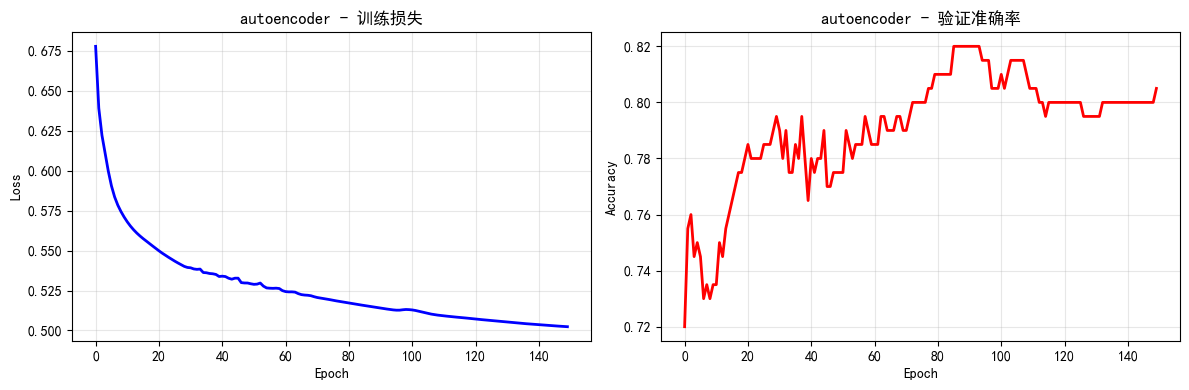


实验结果汇总
autoencoder: 最佳验证准确率 = 0.8200

结果已保存到 cifar10_binary_autoencoder_results.npz


In [6]:
# 第六部分：主程序 - 自编码器降维实验（二分类）
# ============================================

if __name__ == "__main__":
    print("=" * 60)
    print("自编码器降维实验 - 二分类 airplane/automobile")
    print("固定 Ansatz: sequential_su4, 层数=2")
    print("自编码器配置: hidden=[256,64], latent=8, epochs=50, lr=0.001, 输出归一化到 [-1,1]（与 MNIST 实验一致）")
    print("=" * 60)

    # 1. 加载 CIFAR-10 二分类数据
    print("\n步骤1：加载 CIFAR-10 二分类数据")
    train_images, train_labels, test_images, test_labels = load_cifar10_binary()
    print(f"训练集: {train_images.shape[0]} 样本, 测试集: {test_images.shape[0]} 样本")

    # 2. 对每种降维方法进行实验（这里只有自编码器）
    all_results = {}

    for method in DIM_REDUCTION_METHODS:
        print(f"\n{'='*60}")
        print(f"降维方法: {method}")
        print(f"{'='*60}")

        if method == 'autoencoder':
            # 自编码器预处理
            print("\n步骤3：自编码器降维预处理")
            train_dataset, final_scaler, encoder, scaler_for_ae = preprocess_data_autoencoder(
                train_images, train_labels, is_train=True
            )
            test_dataset, _, _, _ = preprocess_data_autoencoder(
                test_images, test_labels, encoder=encoder, scaler_for_ae=scaler_for_ae, final_scaler=final_scaler, is_train=False
            )
        else:
            raise ValueError(f"未知的降维方法: {method}")

        # 3. 训练模型
        print("\n步骤4：训练量子神经网络")
        train_losses, val_accuracies, best_val_acc = train_model(
            train_dataset=train_dataset,
            val_dataset=test_dataset,
            num_epochs=NUM_EPOCHS,
            learning_rate=LEARNING_RATE
        )

        # 存储结果
        all_results[method] = {
            'train_losses': train_losses,
            'val_accuracies': val_accuracies,
            'best_val_acc': best_val_acc
        }

        # 4. 绘制单个实验的曲线
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, 'b-', linewidth=2)
        plt.title(f'{method} - 训练损失')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.grid(True, alpha=0.3)

        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, 'r-', linewidth=2)
        plt.title(f'{method} - 验证准确率')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    # 5. 汇总结果
    print("\n" + "=" * 60)
    print("实验结果汇总")
    print("=" * 60)
    for method, res in all_results.items():
        print(f"{method}: 最佳验证准确率 = {res['best_val_acc']:.4f}")

    # 6. 保存结果
    np.savez('cifar10_binary_autoencoder_results.npz', 
             train_losses=all_results['autoencoder']['train_losses'],
             val_accuracies=all_results['autoencoder']['val_accuracies'],
             best_val_acc=all_results['autoencoder']['best_val_acc'])
    print("\n结果已保存到 cifar10_binary_autoencoder_results.npz")